# 方向交叉与剂量实验的 review_bundle 分析（CPU v1）

直接读取 Drive 中上一轮生成的 `review_bundle.zip`，无需 GPU、Torch、模型、adapter，也不重新推理。

[实验设置与运行说明](../../../docs/experiment_notes/07_appendix_lora_training/71c79617c3717cf1.md)


In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('tqdm') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','tqdm>=4.66'])
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(total=total, initial=initial, desc=label, unit='cell',
               dynamic_ncols=True, leave=True)
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 13 tracked cells.')

Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 13 tracked cells.


In [2]:
%%cell_progress 1/13 Prepare CPU analysis dependencies
cell_stage('Prepare CPU analysis dependencies')

import importlib.util, importlib.metadata, subprocess, sys
requirements={'numpy':'numpy>=1.26','pandas':'pandas>=2.2','matplotlib':'matplotlib>=3.8','tqdm':'tqdm>=4.66'}
missing=[requirement for module,requirement in requirements.items() if importlib.util.find_spec(module) is None]
if missing:subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Markdown
print('CPU only: no Torch, model weights, training or inference.')
print({name:importlib.metadata.version(name) for name in requirements})

Prepare CPU analysis dependencies:   0%|          | 0/13 [00:00<?, ?cell/s]

CPU only: no Torch, model weights, training or inference.
{'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'tqdm': '4.67.3'}


In [3]:
%%cell_progress 2/13 Mount Drive and locate review bundle
cell_stage('Mount Drive and locate review bundle')

from pathlib import Path
# Only change this if the ZIP is not in the original experiment directory.
SOURCE_ZIP_OVERRIDE = ''
OUTPUT_DIR_OVERRIDE = ''
try:in_colab=importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:in_colab=False
if in_colab:
    from google.colab import drive
    drive.mount('/content/drive')
relative='results/qwen27b_handoff_axis_dose_crossover_newgeometry_v1/review_bundle.zip'
project_candidates=[Path('/content/drive/MyDrive/VisualTorque'),Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
    Path.cwd(),Path.cwd()/'VisualTorque']
if SOURCE_ZIP_OVERRIDE:
    SOURCE_ZIP=Path(SOURCE_ZIP_OVERRIDE).expanduser().resolve()
else:
    candidates=[root/relative for root in project_candidates]
    found=sorted({p.resolve() for p in candidates if p.is_file()})
    if not found:
        candidates += [Path('/content/drive/MyDrive/review_bundle.zip'),Path.cwd()/'review_bundle.zip']
        found=sorted({p.resolve() for p in candidates if p.is_file()})
    if len(found)!=1:
        raise FileNotFoundError('Set SOURCE_ZIP_OVERRIDE to the full path of the axis-dose review_bundle.zip. '
            f'Found: {[str(p) for p in found]}. Checked: {[str(p) for p in candidates]}')
    SOURCE_ZIP=found[0]
if not SOURCE_ZIP.is_file():raise FileNotFoundError(SOURCE_ZIP)
if SOURCE_ZIP.parent.name=='qwen27b_handoff_axis_dose_crossover_newgeometry_v1':
    DEFAULT_OUTPUT_BASE=SOURCE_ZIP.parent.parent/'qwen27b_axis_dose_review_cpu_v1'
else:
    DEFAULT_OUTPUT_BASE=SOURCE_ZIP.parent/'qwen27b_axis_dose_review_cpu_v1'
OUTPUT_BASE=Path(OUTPUT_DIR_OVERRIDE).expanduser().resolve() if OUTPUT_DIR_OVERRIDE else DEFAULT_OUTPUT_BASE
print('Read-only source ZIP:',SOURCE_ZIP)

Mount Drive and locate review bundle:   8%|7         | 1/13 [00:00<?, ?cell/s]

Mounted at /content/drive
Read-only source ZIP: /content/drive/MyDrive/VisualTorque/results/qwen27b_handoff_axis_dose_crossover_newgeometry_v1/review_bundle.zip


In [4]:
%%cell_progress 3/13 Configure read-only source and audit outputs
cell_stage('Configure read-only source and audit outputs')

import hashlib, io, itertools, json, math, platform, zipfile
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import PurePosixPath

IMPLEMENTATION_SHA256='sha256:99a3c4f02ce1573183ca92b5d4274219aa939a7372a48b31403c95c19210d7cf'
AUDIT_VERSION='axis-dose-bundle-cpu-1.0'
AUDIT_SEED=20260906
AUDIT_BOOTSTRAP=10000
KEY=['model','scene_id','mapping']
META=['family_id','max_units','side','diagnostic_cell','margin_bin']
CONDITION_FIELDS=['kind','layer','axis','scale','dose','mediator','clamp','condition_id']
MODELS=('native','lora')
ROUTES=('L48_via_L49','L48_via_L55','L49_via_L55')
COMPONENTS=['total_effect','target_block_loss','random_block_loss','specific_loss',
    'self_target','self_random','target_clamped_response','random_clamped_response']
DOSE_FIELDS=['historical_native_reference_norm','recipient_clean_norm','paired_native_clean_norm',
    'requested_payload_norm','fp32_payload_norm','bf16_payload_norm','bf16_payload_over_clean_norm',
    'effective_added_displacement_norm']
INTENTIONALLY_OMITTED={'frozen_crossover_axes.pt','dose_inventory.json'}

def require(condition,message):
    if not bool(condition):raise ValueError(message)

def default_json(value):
    if isinstance(value,np.generic):return value.item()
    if isinstance(value,Path):return str(value)
    raise TypeError(type(value).__name__)

def canonical(value):return json.dumps(value,sort_keys=True,ensure_ascii=False,allow_nan=False,default=default_json)
def digest(value):return 'sha256:'+hashlib.sha256(canonical(value).encode()).hexdigest()

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda:handle.read(1024*1024),b''):h.update(chunk)
    return 'sha256:'+h.hexdigest()

def write_json(path,value):
    path=Path(path);temporary=path.with_suffix(path.suffix+'.tmp')
    temporary.write_text(canonical(value)+'\n',encoding='utf-8');temporary.replace(path)

def freeze(path,identity):
    identity=json.loads(canonical(identity))
    if path.is_file():require(json.loads(path.read_text('utf-8'))['identity']==identity,'Audit settings/input changed; use another output directory.')
    else:write_json(path,{'identity':identity,'created_utc':datetime.now(timezone.utc).isoformat()})
    return digest(identity)

def save(frame,name):
    path=TABLE_DIR/(name+'.csv');temporary=path.with_suffix('.csv.tmp')
    frame.to_csv(temporary,index=False);temporary.replace(path)

def records(frame):return json.loads(frame.to_json(orient='records',double_precision=15))

def show(frame,columns=None,limit=100):
    selected=frame if columns is None else frame[columns]
    with pd.option_context('display.max_rows',limit,'display.max_columns',30,'display.width',180):
        display(selected.round(6))

def strict_bool(series):
    def convert(x):
        if isinstance(x,(bool,np.bool_)):return bool(x)
        if isinstance(x,str) and x.lower() in ('true','false'):return x.lower()=='true'
        raise ValueError(f'Invalid boolean in {series.name}: {x!r}')
    return series.map(convert).astype(bool)

def unique(frame,keys,label):
    require(set(keys)<=set(frame),f'Missing keys in {label}: {set(keys)-set(frame)}')
    require(not frame[keys].isna().any().any(),f'Null key in {label}')
    require(not frame.duplicated(keys).any(),f'Duplicate key in {label}: {keys}')

def finite(frame,fields,label):
    require(set(fields)<=set(frame),f'Missing numeric field in {label}: {set(fields)-set(frame)}')
    require(np.isfinite(frame[fields].to_numpy(dtype=float)).all(),f'Nonfinite field in {label}')

SOURCE_ZIP_HASH=sha256_file(SOURCE_ZIP)
OUTPUT_ROOT=OUTPUT_BASE/SOURCE_ZIP_HASH.split(':')[1][:12]
TABLE_DIR,FIGURE_DIR=OUTPUT_ROOT/'tables',OUTPUT_ROOT/'figures'
for p in (OUTPUT_ROOT,TABLE_DIR,FIGURE_DIR):p.mkdir(parents=True,exist_ok=True)
require(not SOURCE_ZIP.is_relative_to(OUTPUT_ROOT),'Source ZIP must not be inside audit output.')
print('New CPU output directory:',OUTPUT_ROOT)

Configure read-only source and audit outputs:  15%|#5        | 2/13 [00:00<?, ?cell/s]

New CPU output directory: /content/drive/MyDrive/VisualTorque/results/qwen27b_axis_dose_review_cpu_v1/5154fe82d315


In [5]:
%%cell_progress 4/13 Verify archive manifest and source identity
cell_stage('Verify archive manifest and source identity')

def open_bundle(path):
    with zipfile.ZipFile(path) as archive:
        infos=[i for i in archive.infolist() if not i.is_dir()]
        require(sum(i.file_size for i in infos)<512*1024**2,'Bundle uncompressed size exceeds 512 MiB.')
        names=[i.filename for i in infos]
        require(len(names)==len(set(names)),'Duplicate ZIP members.')
        for name in names:
            parts=PurePosixPath(name).parts
            require(not PurePosixPath(name).is_absolute() and '..' not in parts and '\\' not in name
                and not any(':' in part for part in parts),'Invalid ZIP member path.')
        roots=[name[:-len('RUN_COMPLETE.json')] for name in names if name.endswith('RUN_COMPLETE.json')]
        roots=[prefix for prefix in roots if prefix+'frozen_protocol.json' in names and prefix+'analysis/clean_records.csv' in names]
        require(len(roots)==1,'ZIP must contain exactly one completed axis-dose experiment.')
        prefix=roots[0]
        return {name[len(prefix):]:archive.read(name) for name in names if name.startswith(prefix)}

BUNDLE_BYTES=open_bundle(SOURCE_ZIP)

def read_json(name):
    require(name in BUNDLE_BYTES,f'Missing bundle member: {name}')
    return json.loads(BUNDLE_BYTES[name].decode('utf-8'))

def identity(name):return read_json(name)['identity']

def read_table(name):
    key='analysis/'+name+'.csv';require(key in BUNDLE_BYTES,f'Missing source table: {key}')
    identifiers=['model','scene_id','mapping','family_id','side','diagnostic_cell','kind','axis','scale','clamp',
        'condition_id','route','test','contrast','coordinate_source','input_axis','boundary','value']
    frame=pd.read_csv(io.BytesIO(BUNDLE_BYTES[key]),float_precision='round_trip',dtype={k:str for k in identifiers})
    for field in ('correct',):
        if field in frame:frame[field]=strict_bool(frame[field])
    return frame

completion=read_json('RUN_COMPLETE.json')
require(completion['status']=='complete','Source experiment is incomplete.')
manifest=completion['outputs'];missing=[]
for name,expected in tqdm(manifest.items(),desc='Verify bundle file hashes',unit='file'):
    if name not in BUNDLE_BYTES:
        require(name in INTENTIONALLY_OMITTED,f'Unexpected missing completed artifact: {name}')
        missing.append(name);continue
    require('sha256:'+hashlib.sha256(BUNDLE_BYTES[name]).hexdigest()==expected,f'Hash mismatch: {name}')
required_root=['frozen_protocol.json','runtime_lock.json','prompt_inventory.json','scene_manifest.json',
    'geometry_selection.json','condition_plan.json','capture_identity.json','clean_inventory.json','run_identity.json',
    'native_axis_calibration.json','disabled_base_parity.json','historical_native_replay.json','technical_smoke.json',
    'source_shard_hashes.json']
required_tables=['clean_records','intervention_records','signed_state_traces','prescribed_and_realized_doses',
    'specific_block_losses','family_specific_losses','primary_six_tests','primary_family_contrasts',
    'family_additive_effects','dose_response_curves','secondary_dose_and_injection_interactions',
    'paired_signed_projection_changes','boundary_route_changes','behavior_by_weight_range','axis_geometry']
for name in required_root+['analysis/'+name+'.csv' for name in required_tables]+['analysis/paired_behavior.json','analysis/final_integrity.json','analysis/confirmation_control_diagnostics.json']:
    require(name in manifest and name in BUNDLE_BYTES,f'Required hashed artifact missing: {name}')
protocol,runtime=identity('frozen_protocol.json'),identity('runtime_lock.json')
require(protocol['model']=='Qwen/Qwen3.5-27B' and protocol['revision']=='373612cb4f9288fcf550b526d86d85febedd9801','Wrong base checkpoint.')
require(protocol['dtype']=='bfloat16' and protocol['native_numerics_policy']['tf32_matmul'] is False,'Wrong source precision policy.')
require(runtime['float32_matmul_precision']=='highest' and runtime['tf32_matmul'] is False,'Wrong captured numerical precision.')
require(tuple(protocol['doses'])==(-1.0,-.5,.5,1.0) and tuple(protocol['scales'])==('absolute','relative'),'Unexpected dose protocol.')
require(protocol['relative_rule']=='historical_native_norm * recipient_clean_norm / paired_native_clean_norm','Unexpected relative-dose rule.')
N_FAMILIES=int(protocol['n_families'])
require(N_FAMILIES>=2 and N_FAMILIES==completion['n_families'],'Invalid family count.')
require(completion['counts']=={'clean':8*N_FAMILIES,'interventions':560*N_FAMILIES},'Unexpected completed input counts.')
PLAN=identity('condition_plan.json');PLAN_FRAME=pd.DataFrame(PLAN)
require(len(PLAN)==70,'Expected 70 conditions per input.')
unique(PLAN_FRAME,['condition_id'],'condition plan')
for p in PLAN:
    require(set(p)==set(CONDITION_FIELDS),'Unexpected condition fields.')
    require(p['condition_id']==digest({k:v for k,v in p.items() if k!='condition_id'}).split(':')[1][:24],'Condition identity mismatch.')
prompts=identity('prompt_inventory.json');scenes=pd.DataFrame(identity('scene_manifest.json'))
require(digest(prompts)==protocol['prompts'],'Prompt identity mismatch.')
geometry=identity('geometry_selection.json')
require(digest(geometry['families'])==protocol['geometry'],'Geometry selection identity mismatch.')
capture=digest({'protocol':digest(protocol),'runtime':digest(runtime),'axes':manifest['frozen_crossover_axes.pt']})
require(identity('capture_identity.json')['digest']==capture,'Capture identity mismatch.')
require(identity('run_identity.json')['digest']==completion['run_identity'],'Run identity mismatch.')
gates={name:bool(read_json(name)['passed']) for name in ['native_axis_calibration.json','disabled_base_parity.json',
    'historical_native_replay.json','technical_smoke.json','analysis/final_integrity.json']}
require(all(gates.values()),'Source technical/calibration gate failed.')
source_limits={'not_directly_reverified':['axis tensor bytes','clean tensor bytes','per-condition raw candidate logits','original image bytes'],
    'intentionally_absent':missing,'source_exported_margins_used':True,'no_new_inference':True}
AUDIT_ID=freeze(OUTPUT_ROOT/'audit_lock.json',{'version':AUDIT_VERSION,'implementation':IMPLEMENTATION_SHA256,
    'zip_hash':SOURCE_ZIP_HASH,'source_run':completion['run_identity'],'source_manifest':digest(manifest),
    'seed':AUDIT_SEED,'bootstrap':AUDIT_BOOTSTRAP,'source_limits':source_limits,
    'runtime':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'matplotlib':importlib.metadata.version('matplotlib')}})
write_json(OUTPUT_ROOT/'source_integrity.json',{'gates':gates,'limits':source_limits,'audit_identity':AUDIT_ID,'source_zip':str(SOURCE_ZIP)})
print('Completed source verified:',N_FAMILIES,'families; expected omissions:',missing)
print('Raw model forward passes are not re-executed or independently reconstructed from this compact bundle.')

Verify archive manifest and source identity:  23%|##3       | 3/13 [00:00<?, ?cell/s]

Verify bundle file hashes:   0%|          | 0/40 [00:00<?, ?file/s]

Completed source verified: 32 families; expected omissions: ['dose_inventory.json', 'frozen_crossover_axes.pt']
Raw model forward passes are not re-executed or independently reconstructed from this compact bundle.


In [6]:
%%cell_progress 5/13 Validate paired records and reconstruct omitted dose identity
cell_stage('Validate paired records and reconstruct omitted dose identity')

clean=read_table('clean_records');patch=read_table('intervention_records');traces=read_table('signed_state_traces')
doses=read_table('prescribed_and_realized_doses');saved_loss=read_table('specific_block_losses')
unique(clean,KEY,'clean');unique(patch,KEY+['condition_id'],'interventions');unique(traces,KEY+['condition_id','trace_layer'],'traces')
unique(doses,KEY+['condition_id'],'prescribed doses');unique(scenes,['scene_id'],'scenes')
require(len(clean)==8*N_FAMILIES and len(patch)==560*N_FAMILIES and len(traces)==1680*N_FAMILIES,'Incomplete source tables.')
require(len(doses)==320*N_FAMILIES,'Wrong number of dose rows.')
finite(clean,['clean_margin','clean_l48_norm','clean_l49_norm','clean_l55_norm'],'clean')
finite(patch,['margin_shift','centered_score_change'],'interventions')
finite(doses,DOSE_FIELDS,'doses')
require(set(clean.model)==set(MODELS) and set(clean.mapping)=={'forward','reverse'},'Unexpected models/mappings.')
require(clean.groupby(['family_id','model']).size().eq(4).all(),'Expected two mirrors x two mappings per model/family.')
require(clean.groupby('scene_id').size().eq(4).all(),'Each scene must appear in both models and mappings.')
require(patch.groupby(KEY).size().eq(70).all(),'Missing conditions in an input.')
require(traces.groupby(KEY+['condition_id']).trace_layer.apply(lambda s:set(s)=={48,49,55}).all(),'Missing trace layers.')
require(set(clean.scene_id)==set(scenes.scene_id) and scenes.family_id.nunique()==N_FAMILIES,'Scene/family inventory mismatch.')
require(set(scenes.max_units)=={6,7},'Unexpected weight-range strata.')
require(scenes.groupby('family_id').side.apply(lambda s:set(s)=={'left','right'}).all(),'Missing mirror in a physical family.')
scene_lookup=scenes.set_index('scene_id')
for column in META:
    expected=clean.scene_id.map(scene_lookup[column])
    require((clean[column].to_numpy()==expected.to_numpy()).all(),f'Clean scene metadata changed: {column}')
require((clean.correct==(clean.predicted_semantic==clean.side)).all(),'Clean correctness differs from saved semantic prediction.')
require(set(clean.predicted_semantic)<={'left','right','balanced'},'Unexpected clean prediction.')
for label,frame in [('patch',patch),('traces',traces)]:
    merged=frame.merge(clean[KEY+META],on=KEY,suffixes=('_record','_clean'),validate='many_to_one',how='left',indicator=True)
    require((merged['_merge']=='both').all(),f'{label} contains unknown clean inputs.')
    for column in META:require((merged[column+'_record']==merged[column+'_clean']).all(),f'{label} metadata mismatch: {column}')
    merged=frame.merge(PLAN_FRAME,on='condition_id',suffixes=('_record','_plan'),validate='many_to_one',how='left',indicator=True)
    require((merged['_merge']=='both').all(),f'Unexpected condition in {label}.')
    for column in CONDITION_FIELDS[:-1]:require((merged[column+'_record']==merged[column+'_plan']).all(),f'Condition metadata mismatch: {column}')
# Complete model x scene x mapping x condition Cartesian product, not counts alone.
expected_keys=pd.MultiIndex.from_product([MODELS,sorted(scenes.scene_id),['forward','reverse']],names=KEY)
require(set(map(tuple,clean[KEY].to_numpy()))==set(expected_keys),'Incomplete paired clean Cartesian product.')

def geometry_key_from_row(row):
    sides=tuple(((int(row[s+'_units']),int(row[s+'_distance'])),) for s in ('left','right'))
    return min(sides,sides[::-1])

excluded={canonical(key) for group in geometry['excluded'].values() for key in group}
family_geometries={}
for row in scenes.to_dict('records'):
    key=geometry_key_from_row(row)
    require(canonical(key) not in excluded,'Confirmed geometry overlaps a frozen exclusion group.')
    require(row['net_torque']==row['left_units']*row['left_distance']-row['right_units']*row['right_distance'],'Torque label mismatch.')
    require((row['net_torque']>0)==(row['side']=='left') and row['net_torque']!=0,'Side label mismatch.')
    require(max(row['left_units'],row['right_units'])==row['max_units'],'Weight-range label mismatch.')
    require(row['image_sha256']==protocol['images'][row['scene_id']],'Image hash inventory mismatch.')
    family_geometries.setdefault(row['family_id'],set()).add(key)
require(all(len(v)==1 for v in family_geometries.values()) and len(set.union(*family_geometries.values()))==N_FAMILIES,'Family geometry is not independent.')
prompt_frame=pd.DataFrame(prompts).rename(columns={'mapping':'mapping'})
unique(prompt_frame,['scene_id','mapping'],'prompts')
require(len(prompt_frame)==4*N_FAMILIES and set(prompt_frame.scene_id)==set(scenes.scene_id),'Prompt inventory count mismatch.')
for row in prompts:
    require(set(row['labels'])=={'A','B','C'} and set(row['semantics'])=={'left','right','balanced'},'Invalid prompt candidates.')
    require(row['image_sha256']==protocol['images'][row['scene_id']],'Prompt image hash mismatch.')
# Reconstruct the deliberately omitted dose_inventory.json identity exactly from its CSV.
require(list(doses.columns)==KEY+CONDITION_FIELDS+DOSE_FIELDS,'Dose CSV schema/order differs from original producer.')
reconstructed_dose_digest=digest(doses.to_dict('records'))
if 'dose_inventory.json' in BUNDLE_BYTES:
    require(digest(identity('dose_inventory.json'))==reconstructed_dose_digest,'Dose CSV does not match included dose inventory.')
run_digest=digest({'capture':capture,'clean':digest(identity('clean_inventory.json')),'doses':reconstructed_dose_digest,'plan':PLAN})
require(run_digest==completion['run_identity'],'Dose CSV / clean inventory / plan cannot reproduce completed run identity.')
write_json(OUTPUT_ROOT/'reconstructed_identity.json',{'run':run_digest,'dose_inventory_digest':reconstructed_dose_digest,'matches':True})
print('Complete paired tables, family exclusions, labels and omitted dose identity reconstructed.')

Validate paired records and reconstruct omitted dose identity:  31%|###       | 4/13 [00:00<?, ?cell/s]

Complete paired tables, family exclusions, labels and omitted dose identity reconstructed.


In [7]:
%%cell_progress 6/13 Audit actual doses and intervention controls
cell_stage('Audit actual doses and intervention controls')

def compare_tables(current,saved,keys,values,label,atol=1e-10,rtol=1e-9):
    unique(current,keys,label+' current');unique(saved,keys,label+' saved')
    a=current[keys+values].rename(columns={v:v+'__current' for v in values})
    b=saved[keys+values].rename(columns={v:v+'__saved' for v in values})
    joined=a.merge(b,on=keys,validate='one_to_one',how='outer',indicator=True)
    require((joined['_merge']=='both').all(),label+' keys differ.')
    diagnostics=[]
    for value in values:
        x=joined[value+'__current'].to_numpy(dtype=float);y=joined[value+'__saved'].to_numpy(dtype=float)
        ok=np.isfinite(x).all() and np.isfinite(y).all() and np.allclose(x,y,atol=atol,rtol=rtol)
        diagnostics.append({'table':label,'column':value,'max_absolute_error':float(np.max(np.abs(x-y))), 'passed':bool(ok)})
    require(all(r['passed'] for r in diagnostics),label+' numeric values differ: '+str(diagnostics))
    return diagnostics

checks=[]
axis_geometry=read_table('axis_geometry')
unique(axis_geometry,['axis'],'axis geometry');finite(axis_geometry,['native_norm','lora_norm','signed_cosine'],'axis geometry')
require(set(axis_geometry.axis)=={'semantic','A>B','B>A','A>C','C>A','B>C','C>B'},'Incomplete coordinate summary.')
require((axis_geometry.native_norm>0).all() and (axis_geometry.lora_norm>0).all(),'Zero/negative direction norm.')
require(np.allclose(axis_geometry.native_norm,axis_geometry.lora_norm,rtol=1e-5,atol=0),'Cross-axis norm matching failed.')
require((axis_geometry.signed_cosine.abs()<=1.000001).all(),'Invalid coordinate cosine.')
save(axis_geometry,'axis_geometry');show(axis_geometry)
add_records=patch[patch.kind=='add']
checks+=compare_tables(add_records,doses,KEY+['condition_id'],DOSE_FIELDS,'recorded vs planned doses')
for model in MODELS:
    inv=pd.DataFrame([dict(model=r['model'],scene_id=r['scene_id'],mapping=r['mapping'],
        **{'clean_l'+l+'_norm':n for l,n in r['norms'].items()}) for r in identity('clean_inventory.json') if r['model']==model])
    checks+=compare_tables(clean[clean.model==model],inv,KEY,['clean_l48_norm','clean_l49_norm','clean_l55_norm'],'clean norm inventory '+model)
own=clean[KEY+['clean_l48_norm','clean_l49_norm','clean_l55_norm']]
joined=doses.merge(own,on=KEY,validate='many_to_one')
native=clean[clean.model=='native'][['scene_id','mapping','clean_l48_norm','clean_l49_norm','clean_l55_norm']].rename(
    columns={f'clean_l{l}_norm':f'native_l{l}_norm' for l in (48,49,55)})
joined=joined.merge(native,on=['scene_id','mapping'],validate='many_to_one')
for layer in (48,49,55):
    sub=joined[joined.layer==layer]
    require(np.allclose(sub.recipient_clean_norm,sub[f'clean_l{layer}_norm'],atol=1e-10,rtol=1e-9),'Wrong recipient clean norm anchor.')
    require(np.allclose(sub.paired_native_clean_norm,sub[f'native_l{layer}_norm'],atol=1e-10,rtol=1e-9),'Wrong paired Native norm anchor.')
expected=joined.dose.abs()*joined.historical_native_reference_norm*np.where(joined.scale=='relative',
    joined.recipient_clean_norm/joined.paired_native_clean_norm,1.0)
require(np.allclose(expected,joined.requested_payload_norm,atol=1e-10,rtol=1e-9),'Prescribed dose formula mismatch.')
require(np.allclose(joined.bf16_payload_norm/joined.recipient_clean_norm,joined.bf16_payload_over_clean_norm,atol=1e-10,rtol=1e-9),'Relative payload formula mismatch.')
require(((joined.bf16_payload_norm-joined.requested_payload_norm).abs()/joined.requested_payload_norm<.005).all(),'BF16 payload outside source tolerance.')
for layer,field in [(48,'projection_on_native'),(49,'projection_on_native'),(55,'projection_on_native')]:
    finite(traces[traces.trace_layer==layer],['displacement_from_own_clean_norm',field],f'L{layer} traces')
finite(traces[traces.trace_layer.isin([49,55])],['projection_on_lora'],'LoRA-coordinate traces')
source_edits=traces[(traces.kind!='self')&(traces.trace_layer==traces.layer)][KEY+['condition_id','actual_local_edit_norm']]
observed=patch[patch.kind!='self'].merge(source_edits,on=KEY+['condition_id'],validate='one_to_one')
require(np.allclose(observed.actual_local_edit_norm,observed.effective_added_displacement_norm,atol=1e-4,rtol=1e-5),'Actual hook edit and BF16 realized displacement differ.')
clamp_traces=traces[(traces.mediator!=0)&(traces.trace_layer==traces.mediator)]
finite(clamp_traces,['removed_projection_signed','removed_projection_abs','clamp_residual_signed','actual_local_edit_norm'],'clamp traces')
require(np.allclose(clamp_traces.removed_projection_signed.abs(),clamp_traces.removed_projection_abs,atol=1e-10,rtol=1e-9),'Removed absolute/signed projection mismatch.')
control={'self_max_margin_change':float(patch.loc[patch.kind=='self','margin_shift'].abs().max()),
    'self_max_centered_score_change':float(patch.loc[patch.kind=='self','centered_score_change'].max()),
    'clamp_max_abs_residual':float(clamp_traces.clamp_residual_signed.abs().max())}
require(max(control.values())<=.15,'Source technical tolerance exceeded.')
native_repeat=patch[(patch.model=='native')&(patch.kind!='self')].pivot(index=['scene_id','mapping','kind','layer','axis','dose','mediator','clamp'],columns='scale',values='margin_shift')
control['native_repeat_max_error']=float((native_repeat.absolute-native_repeat.relative).abs().max())
require(control['native_repeat_max_error']<=.15,'Identical Native dose repeat differs.')
relative=doses[doses.scale=='relative'].pivot(index=['scene_id','mapping','layer','axis','dose'],columns='model',values='bf16_payload_over_clean_norm')
control['relative_payload_max_fractional_mismatch']=float(((relative.lora-relative.native)/relative.native).abs().max())
require(control['relative_payload_max_fractional_mismatch']<=.01,'Relative BF16 dose mismatch.')
save(pd.DataFrame(checks),'numeric_reconstruction_checks');write_json(OUTPUT_ROOT/'control_checks.json',control)
show(pd.DataFrame([control]))
print('Dose and trace checks passed. Clamp-axis norm has not been substituted for removed dose.')

Audit actual doses and intervention controls:  38%|###8      | 5/13 [00:00<?, ?cell/s]

,axis,native_norm,lora_norm,signed_cosine
0,semantic,13.433455,13.433455,0.689654
1,A>B,24.639637,24.639639,0.643743
2,B>A,24.639637,24.639635,0.233325
3,A>C,24.639635,24.639624,0.626226
4,C>A,24.639635,24.639639,0.680493
5,B>C,24.639635,24.639629,0.612808
6,C>B,24.639631,24.639627,0.271502


,self_max_margin_change,self_max_centered_score_change,clamp_max_abs_residual,native_repeat_max_error,relative_payload_max_fractional_mismatch
0,0.0,0.0,0.090672,0.0,0.000249


Dose and trace checks passed. Clamp-axis norm has not been substituted for removed dose.


In [8]:
%%cell_progress 7/13 Reconstruct losses and verify original six primary tests
cell_stage('Reconstruct losses and verify original six primary tests')

loss_rows=[]
for key,group in tqdm(patch.groupby(KEY,sort=True),desc='Rebuild specific block losses',unit='input'):
    table={tuple(r[k] for k in ['kind','layer','axis','scale','dose','mediator','clamp']):r['margin_shift'] for r in group.to_dict('records')}
    require(len(table)==70,'Ambiguous intervention records.')
    meta={k:group.iloc[0][k] for k in KEY+META}
    for scale in ('absolute','relative'):
        for layer,mediator in [(48,49),(48,55),(49,55)]:
            for source in (('native',) if layer==48 else MODELS):
                for clamp in MODELS:
                    total=table[('add',layer,source,scale,1.0,0,'none')]
                    target=table[('block',layer,source,scale,1.0,mediator,clamp)]
                    random=table[('block',layer,source,scale,1.0,mediator,'random')]
                    self_target=table[('self',mediator,'none','none',0.0,mediator,clamp)]
                    self_random=table[('self',mediator,'none','none',0.0,mediator,'random')]
                    loss_rows.append({**meta,'route':f'L{layer}_via_L{mediator}','axis':source,'scale':scale,'clamp':clamp,
                        'total_effect':total,'target_clamped_response':target,'random_clamped_response':random,
                        'self_target':self_target,'self_random':self_random,
                        'target_block_loss':total-target+self_target,'random_block_loss':total-random+self_random,
                        'specific_loss':random-target+self_target-self_random})
loss=pd.DataFrame(loss_rows)
loss_keys=KEY+['route','axis','scale','clamp']
checks+=compare_tables(loss,saved_loss,loss_keys,COMPONENTS,'specific block losses')
save(loss,'reconstructed_specific_losses')
# These exact original estimators reproduce the prespecified six tests, rather
# than treating this later CPU audit as another independent confirmation.
SEED=int(protocol['seed'])
BOOTSTRAP_REPLICATES=int(protocol['bootstrap'])
SIGNFLIP_REPLICATES=int(protocol['signflip'])
def stable_key(value,seed=None):
    return hashlib.sha256(f'{SEED if seed is None else seed}:{value!r}'.encode()).hexdigest()
def estimate_paired(values,key,with_test=False):
    values=np.asarray(values,dtype=float)
    require(values.ndim==1 and len(values)>=2 and np.isfinite(values).all(),'Invalid independent-family effects.')
    rng=np.random.default_rng(int(stable_key(('statistics',key))[:16],16))
    boot=np.empty(BOOTSTRAP_REPLICATES)
    for start in range(0,BOOTSTRAP_REPLICATES,256):
        stop=min(start+256,BOOTSTRAP_REPLICATES)
        boot[start:stop]=values[rng.integers(0,len(values),size=(stop-start,len(values)))].mean(axis=1)
    result={'n_families':len(values),'estimate':float(values.mean()),'ci_low':float(np.quantile(boot,.025)),
        'ci_high':float(np.quantile(boot,.975)),'negative_families':int((values<0).sum())}
    if with_test:
        exceed=0;observed=abs(values.mean())
        for start in range(0,SIGNFLIP_REPLICATES,1024):
            count=min(1024,SIGNFLIP_REPLICATES-start)
            signs=rng.integers(0,2,size=(count,len(values)))*2-1
            exceed+=int((np.abs((signs*values).mean(axis=1))>=observed-1e-12).sum())
        result['p_two_sided']=(exceed+1)/(SIGNFLIP_REPLICATES+1)
    return result

def holm(pvalues):
    pvalues=np.asarray(pvalues,dtype=float);order=np.argsort(pvalues)
    adjusted=np.empty(len(pvalues));running=0.0
    for i,index in enumerate(order):
        running=max(running,(len(pvalues)-i)*pvalues[index]);adjusted[index]=min(1.0,running)
    return adjusted.tolist()

def family_average(frame,keys,value):
    # A family contributes four equally weighted observations: two mirrors x two maps.
    counts=frame.groupby(['family_id',*keys],dropna=False).size()
    require((counts==4).all(),'Family cell must contain both mirrors and both mappings.')
    return frame.groupby(['family_id',*keys],as_index=False,dropna=False)[value].mean()
family_loss=family_average(loss,['model','route','axis','scale','clamp'],'specific_loss')
checks+=compare_tables(family_loss,read_table('family_specific_losses'),['family_id','model','route','axis','scale','clamp'],['specific_loss'],'family losses')
primary=[];primary_values=[]
for route in ROUTES:
    f=family_loss[(family_loss.route==route)&(family_loss.axis=='native')&(family_loss.scale=='relative')]
    w=f.pivot(index='family_id',columns=['model','clamp'],values='specific_loss')
    require(len(w)==N_FAMILIES and not w.isna().any().any(),'Incomplete primary pairs.')
    changes=w[('lora','native')]-w[('native','native')]
    interaction=(w[('lora','lora')]-w[('lora','native')])-(w[('native','lora')]-w[('native','native')])
    for name,values in [('recipient_change_native_clamp',changes),('model_x_clamp_source',interaction)]:
        key=route+'__'+name
        primary.append({'test':key,'route':route,'contrast':name,**estimate_paired(values,key,True)})
        primary_values.extend({'test':key,'family_id':fid,'value':float(v)} for fid,v in values.items())
for row,p in zip(primary,holm([r['p_two_sided'] for r in primary])):row['p_holm']=p
primary=pd.DataFrame(primary);primary_values=pd.DataFrame(primary_values)
checks+=compare_tables(primary,read_table('primary_six_tests'),['test'],['estimate','ci_low','ci_high','p_two_sided','p_holm','negative_families','n_families'],'six primary tests')
checks+=compare_tables(primary_values,read_table('primary_family_contrasts'),['test','family_id'],['value'],'primary family contrasts')
save(primary,'verified_primary_six_tests');save(primary_values,'verified_primary_family_contrasts')
save(pd.DataFrame(checks),'numeric_reconstruction_checks')
show(primary,['route','contrast','n_families','estimate','ci_low','ci_high','p_holm'])
print('Original six tests reproduced, including their original multiplicity correction.')

Reconstruct losses and verify original six primary tests:  46%|####6     | 6/13 [00:00<?, ?cell/s]

Rebuild specific block losses:   0%|          | 0/256 [00:00<?, ?input/s]

,route,contrast,n_families,estimate,ci_low,ci_high,p_holm
0,L48_via_L49,recipient_change_native_clamp,32,0.094727,-0.015625,0.220703,0.410013
1,L48_via_L49,model_x_clamp_source,32,-0.000977,-0.036133,0.032227,0.930986
2,L48_via_L55,recipient_change_native_clamp,32,-0.146484,-0.205078,-0.081055,0.001556
3,L48_via_L55,model_x_clamp_source,32,-0.028320,-0.092773,0.035156,0.817462
4,L49_via_L55,recipient_change_native_clamp,32,-0.090820,-0.135742,-0.041016,0.006332
5,L49_via_L55,model_x_clamp_source,32,0.054688,0.005859,0.102539,0.143125


Original six tests reproduced, including their original multiplicity correction.


In [9]:
%%cell_progress 8/13 Analyze natural behavior and boundaries
cell_stage('Analyze natural behavior and boundaries')

def summarize_values(values,key):
    x=np.asarray(values,dtype=float)
    require(x.ndim==1 and len(x)>0 and np.isfinite(x).all(),'Invalid family values for '+str(key))
    result={'n_families':len(x),'estimate':float(x.mean()),'ci_low':None,'ci_high':None}
    if len(x)<2:return result
    rng=np.random.default_rng(int(hashlib.sha256(f'{AUDIT_SEED}:{key!r}'.encode()).hexdigest()[:16],16))
    means=np.empty(AUDIT_BOOTSTRAP)
    for start in range(0,AUDIT_BOOTSTRAP,256):
        end=min(start+256,AUDIT_BOOTSTRAP)
        means[start:end]=x[rng.integers(0,len(x),size=(end-start,len(x)))].mean(axis=1)
    result.update(ci_low=float(np.quantile(means,.025)),ci_high=float(np.quantile(means,.975)))
    return result

def paired_model_effect(frame,value,key):
    by_family=frame.groupby(['family_id','model'])[value].mean().unstack('model')
    require(set(by_family)==set(MODELS) and not by_family.isna().any().any(),'Unpaired model families: '+str(key))
    return {'native_mean':float(by_family.native.mean()),'lora_mean':float(by_family.lora.mean()),
        **summarize_values(by_family.lora-by_family.native,key)}

def source_interaction(frame,value,source_column,key):
    w=frame.groupby(['family_id','model',source_column])[value].mean().unstack(['model',source_column])
    require(set(w.columns)==set(itertools.product(MODELS,MODELS)) and not w.isna().any().any(),'Incomplete 2 x 2 interaction: '+str(key))
    native_gain=w[('native','lora')]-w[('native','native')]
    lora_gain=w[('lora','lora')]-w[('lora','native')]
    return {'native_recipient_native_axis':float(w[('native','native')].mean()),
        'native_recipient_lora_axis':float(w[('native','lora')].mean()),
        'lora_recipient_native_axis':float(w[('lora','native')].mean()),
        'lora_recipient_lora_axis':float(w[('lora','lora')].mean()),
        'native_axis_swap_gain':float(native_gain.mean()),'lora_axis_swap_gain':float(lora_gain.mean()),
        **summarize_values(lora_gain-native_gain,key)}

def subsets(frame):
    yield 'all','all',frame
    for field in ['max_units','side','mapping','diagnostic_cell']:
        for value in sorted(frame[field].unique()):yield field,str(value),frame[frame[field]==value]

def paired_factor_difference(frame,value,factor,left,right,key):
    w=frame.groupby(['family_id','model',factor])[value].mean().unstack(['model',factor])
    require(set(w.columns)==set(itertools.product(MODELS,(left,right))),'Unexpected within-family factor levels: '+str(key))
    require(not w.isna().any().any(),'Incomplete paired within-family factor: '+str(key))
    delta_right=w[('lora',right)]-w[('native',right)]
    delta_left=w[('lora',left)]-w[('native',left)]
    return summarize_values(delta_right-delta_left,key)

def independent_group_difference(left,right,key):
    a,b=np.asarray(left,dtype=float),np.asarray(right,dtype=float)
    require(len(a)>0 and len(b)>0 and np.isfinite(a).all() and np.isfinite(b).all(),'Invalid independent groups.')
    result={'n_left_families':len(a),'n_right_families':len(b),'estimate':float(b.mean()-a.mean()),'ci_low':None,'ci_high':None}
    if min(len(a),len(b))<2:return result
    rng=np.random.default_rng(int(hashlib.sha256(f'{AUDIT_SEED}:{key!r}'.encode()).hexdigest()[:16],16))
    differences=np.empty(AUDIT_BOOTSTRAP)
    for start in range(0,AUDIT_BOOTSTRAP,256):
        end=min(start+256,AUDIT_BOOTSTRAP);n=end-start
        differences[start:end]=b[rng.integers(0,len(b),size=(n,len(b)))].mean(1)-a[rng.integers(0,len(a),size=(n,len(a)))].mean(1)
    result.update(ci_low=float(np.quantile(differences,.025)),ci_high=float(np.quantile(differences,.975)))
    return result

behavior_rows=[]
for scope,value,sub in subsets(clean):
    behavior_rows.append({'scope':scope,'value':value,'inputs_per_model':len(sub)//2,
        'native_correct':int(sub.loc[sub.model=='native','correct'].sum()),
        'lora_correct':int(sub.loc[sub.model=='lora','correct'].sum()),
        **paired_model_effect(sub,'correct',('accuracy',scope,value))})
behavior=pd.DataFrame(behavior_rows);save(behavior,'behavior_by_boundary')
paired_clean=clean.pivot(index=['family_id','scene_id','mapping'],columns='model',values='correct').reset_index()
paired_clean['transition']=np.select([~paired_clean.native & paired_clean.lora,paired_clean.native & ~paired_clean.lora,
    paired_clean.native & paired_clean.lora],['repaired','regressed','both_correct'],default='both_wrong')
transition_counts=paired_clean.transition.value_counts().reindex(['repaired','regressed','both_correct','both_wrong'],fill_value=0)
save(paired_clean,'behavior_transitions_by_input')
transition_table=transition_counts.rename_axis('transition').rename('paired_inputs').reset_index();save(transition_table,'behavior_transition_counts')
consistency=[]
for model in MODELS:
    sub=clean[clean.model==model]
    mapping_agreement=sub.pivot(index='scene_id',columns='mapping',values='predicted_semantic')
    all_correct=sub.groupby('family_id').correct.all()
    consistency.append({'model':model,'all_four_inputs_correct_families':int(all_correct.sum()),'families':len(all_correct),
        'mapping_prediction_agreement':float((mapping_agreement.forward==mapping_agreement.reverse).mean())})
consistency=pd.DataFrame(consistency);save(consistency,'behavior_family_consistency')
natural_margin=paired_model_effect(clean,'clean_margin','natural_margin');write_json(OUTPUT_ROOT/'natural_margin_summary.json',natural_margin)
prior_behavior=read_json('analysis/paired_behavior.json');overall=behavior.iloc[0]
require(math.isclose(overall.native_mean,prior_behavior['native_accuracy'],abs_tol=1e-10) and
    math.isclose(overall.lora_mean,prior_behavior['lora_accuracy'],abs_tol=1e-10) and
    math.isclose(overall.estimate,prior_behavior['estimate'],abs_tol=1e-10),'Natural accuracy disagrees with original report.')
show(behavior);show(transition_table);show(consistency)
print('Accuracy intervals use independent physical families; input transition counts are descriptive.')

Analyze natural behavior and boundaries:  54%|#####3    | 7/13 [00:00<?, ?cell/s]

,scope,value,inputs_per_model,native_correct,lora_correct,native_mean,lora_mean,n_families,estimate,ci_low,ci_high
0,all,all,128,75,117,0.585938,0.914062,32,0.328125,0.226562,0.414062
1,max_units,6,64,37,60,0.578125,0.937500,16,0.359375,0.218750,0.453125
2,max_units,7,64,38,57,0.593750,0.890625,16,0.296875,0.140625,0.437500
3,side,left,64,63,59,0.984375,0.921875,32,-0.062500,-0.171875,0.015625
4,side,right,64,12,58,0.187500,0.906250,32,0.718750,0.593750,0.828125
5,mapping,forward,64,32,58,0.500000,0.906250,32,0.406250,0.281250,0.500000
6,mapping,reverse,64,43,59,0.671875,0.921875,32,0.250000,0.140625,0.359375
7,diagnostic_cell,both_cues_aligned,32,23,32,0.718750,1.000000,8,0.281250,0.187500,0.375000
8,diagnostic_cell,distance_conflict,48,27,37,0.562500,0.770833,12,0.208333,-0.020833,0.395833
9,diagnostic_cell,weight_conflict,48,25,48,0.520833,1.000000,12,0.479167,0.416667,0.541667


,transition,paired_inputs
0,repaired,47
1,regressed,5
2,both_correct,70
3,both_wrong,6


,model,all_four_inputs_correct_families,families,mapping_prediction_agreement
0,native,1,32,0.828125
1,lora,29,32,0.984375


Accuracy intervals use independent physical families; input transition counts are descriptive.


In [10]:
%%cell_progress 9/13 Analyze signed doses and injection-axis interactions
cell_stage('Analyze signed doses and injection-axis interactions')

adds=patch[patch.kind=='add'].copy()
family_add=family_average(adds,['model','layer','axis','scale','dose'],'margin_shift')
checks+=compare_tables(family_add,read_table('family_additive_effects'),['family_id','model','layer','axis','scale','dose'],['margin_shift'],'additive family means')
save(family_add,'family_additive_effects')
curves=[]
for keys,sub in family_add.groupby(['model','layer','axis','scale','dose']):
    curves.append(dict(zip(['model','layer','axis','scale','dose'],keys),**summarize_values(sub.margin_shift,('curve',keys))))
curves=pd.DataFrame(curves);save(curves,'dose_response_curves')
total_changes=[];dose_modification=[];injection_cross=[];oddness=[]
for keys,sub in adds.groupby(['layer','axis','scale','dose']):
    total_changes.append(dict(zip(['layer','axis','scale','dose'],keys),**paired_model_effect(sub,'margin_shift',('total',keys))))
for keys,sub in adds.groupby(['layer','axis','dose']):
    dose_modification.append(dict(zip(['layer','axis','dose'],keys),
        **paired_factor_difference(sub,'margin_shift','scale','absolute','relative',('dose_matching_modification',keys))))
for keys,sub in adds[adds.layer.isin([49,55])].groupby(['layer','scale','dose']):
    injection_cross.append(dict(zip(['layer','scale','dose'],keys),**source_interaction(sub,'margin_shift','axis',('injection_cross',keys))))
for keys,sub in family_add.groupby(['layer','axis','scale']):
    w=sub.pivot(index='family_id',columns=['model','dose'],values='margin_shift')
    for amplitude in (.5,1.0):
        values={model:w[(model,amplitude)]+w[(model,-amplitude)] for model in MODELS}
        oddness.append(dict(zip(['layer','axis','scale'],keys),amplitude=amplitude,
            native_asymmetry=float(values['native'].mean()),lora_asymmetry=float(values['lora'].mean()),
            **summarize_values(values['lora']-values['native'],('dose_asymmetry',keys,amplitude))))
total_changes,dose_modification,injection_cross,oddness=map(pd.DataFrame,(total_changes,dose_modification,injection_cross,oddness))
for frame,name in [(total_changes,'total_additive_model_changes'),(dose_modification,'dose_matching_modification'),
    (injection_cross,'injection_axis_interactions'),(oddness,'positive_negative_asymmetry')]:save(frame,name)
# Cross-check original predeclared secondary point estimates; use descriptive new CIs only.
original_secondary=read_table('secondary_dose_and_injection_interactions')
secondary_rebuilt=pd.concat([
    dose_modification[(dose_modification.axis=='native')&(dose_modification.dose==1)].assign(contrast='dose_matching_modification'),
    injection_cross[(injection_cross.scale=='relative')&(injection_cross.dose==1)].assign(contrast='model_x_injection_source')],ignore_index=True)
checks+=compare_tables(secondary_rebuilt,original_secondary,['contrast','layer'],['estimate'],'original secondary point estimates')
print('Total response, fixed Native injection axis, +1 dose:')
show(total_changes[(total_changes.axis=='native')&(total_changes.dose==1)])
print('Injection-source crossover, relative +1 (secondary; not the clamp interaction in the primary table):')
show(injection_cross[(injection_cross.scale=='relative')&(injection_cross.dose==1)])
print('Positive/negative asymmetry: E(+a)+E(-a); zero corresponds to odd response at these two doses.')
show(oddness[(oddness.axis=='native')&(oddness.scale=='relative')&(oddness.amplitude==1)])

Analyze signed doses and injection-axis interactions:  62%|######1   | 8/13 [00:00<?, ?cell/s]

Total response, fixed Native injection axis, +1 dose:


,layer,axis,scale,dose,native_mean,lora_mean,n_families,estimate,ci_low,ci_high
3,48,native,absolute,1.0,0.693359,0.569336,32,-0.124023,-0.246094,0.014648
7,48,native,relative,1.0,0.693359,0.607422,32,-0.085937,-0.220703,0.061523
19,49,native,absolute,1.0,0.612305,0.578125,32,-0.034180,-0.117187,0.060547
23,49,native,relative,1.0,0.612305,0.640625,32,0.028320,-0.068384,0.138696
35,55,native,absolute,1.0,0.838867,1.101563,32,0.262695,0.203125,0.328125
39,55,native,relative,1.0,0.838867,1.208008,32,0.369141,0.299805,0.441431


Injection-source crossover, relative +1 (secondary; not the clamp interaction in the primary table):


,layer,scale,dose,native_recipient_native_axis,native_recipient_lora_axis,lora_recipient_native_axis,lora_recipient_lora_axis,native_axis_swap_gain,lora_axis_swap_gain,n_families,estimate,ci_low,ci_high
7,49,relative,1.0,0.612305,0.601562,0.640625,0.628906,-0.010742,-0.011719,32,-0.000977,-0.027344,0.027344
15,55,relative,1.0,0.838867,1.023437,1.208008,1.904297,0.184570,0.696289,32,0.511719,0.373047,0.627930


Positive/negative asymmetry: E(+a)+E(-a); zero corresponds to odd response at these two doses.


,layer,axis,scale,amplitude,native_asymmetry,lora_asymmetry,n_families,estimate,ci_low,ci_high
3,48,native,relative,1.0,-0.108398,-0.708008,32,-0.599609,-0.789062,-0.392578
11,49,native,relative,1.0,-0.068359,-0.542969,32,-0.474609,-0.623047,-0.300781
19,55,native,relative,1.0,-0.030273,-0.520508,32,-0.490234,-0.607422,-0.358398


In [11]:
%%cell_progress 10/13 Decompose block losses and boundary interactions
cell_stage('Decompose block losses and boundary interactions')

decomposition=[];clamp_cross=[];boundaries=[];boundary_interactions=[]
for keys,sub in loss[(loss.axis=='native')&(loss.clamp=='native')].groupby(['route','scale']):
    for component in COMPONENTS:
        decomposition.append({'route':keys[0],'scale':keys[1],'component':component,
            **paired_model_effect(sub,component,('decomposition',keys,component))})
for keys,sub in loss.groupby(['route','axis','scale']):
    clamp_cross.append(dict(zip(['route','injection_axis','scale'],keys),**source_interaction(sub,'specific_loss','clamp',('clamp_cross',keys))))
core=loss[(loss.axis=='native')&(loss.clamp=='native')&(loss.scale=='relative')]
for route,sub in core.groupby('route'):
    for field,value,group in subsets(sub):
        boundaries.append({'route':route,'scope':field,'value':value,**paired_model_effect(group,'specific_loss',('route_boundary',route,field,value))})
    for factor,left,right in [('side','left','right'),('mapping','forward','reverse')]:
        boundary_interactions.append({'route':route,'contrast':right+' minus '+left,'factor':factor,
            **paired_factor_difference(sub,'specific_loss',factor,left,right,('boundary_interaction',route,factor))})
    w=sub.groupby(['family_id','max_units','model']).specific_loss.mean().unstack('model').reset_index()
    a=w[w.max_units==6];b=w[w.max_units==7]
    require(set(a.family_id).isdisjoint(b.family_id),'6/7 strata must be independent family groups.')
    boundary_interactions.append({'route':route,'contrast':'7 minus 6','factor':'max_units',
        **independent_group_difference(a.lora-a.native,b.lora-b.native,('units_interaction',route))})
decomposition,clamp_cross,boundaries,boundary_interactions=map(pd.DataFrame,(decomposition,clamp_cross,boundaries,boundary_interactions))
for frame,name in [(decomposition,'block_loss_decomposition'),(clamp_cross,'clamp_axis_interactions'),
    (boundaries,'route_boundary_changes'),(boundary_interactions,'route_boundary_interactions')]:save(frame,name)
print('Separate total response, target/random block losses and their difference:')
show(decomposition[(decomposition.scale=='relative')&decomposition.component.isin(['total_effect','target_block_loss','random_block_loss','specific_loss'])])
print('Relative +1, Native injection: full recipient-model x clamp-source cells:')
show(clamp_cross[(clamp_cross.scale=='relative')&(clamp_cross.injection_axis=='native')])
print('Boundary estimates (secondary pointwise intervals):')
show(boundaries[boundaries.scope.isin(['max_units','side','diagnostic_cell'])])
show(boundary_interactions)

Decompose block losses and boundary interactions:  69%|######9   | 9/13 [00:00<?, ?cell/s]

Separate total response, target/random block losses and their difference:


,route,scale,component,native_mean,lora_mean,n_families,estimate,ci_low,ci_high
8,L48_via_L49,relative,total_effect,0.693359,0.607422,32,-0.085937,-0.219727,0.060547
9,L48_via_L49,relative,target_block_loss,0.568359,0.654297,32,0.085937,-0.024414,0.211914
10,L48_via_L49,relative,random_block_loss,0.007812,-0.000977,32,-0.008789,-0.024414,0.008789
11,L48_via_L49,relative,specific_loss,0.560547,0.655273,32,0.094727,-0.015625,0.217773
24,L48_via_L55,relative,total_effect,0.693359,0.607422,32,-0.085937,-0.216797,0.066406
25,L48_via_L55,relative,target_block_loss,0.217773,0.075195,32,-0.142578,-0.202148,-0.075195
26,L48_via_L55,relative,random_block_loss,-0.001953,0.001953,32,0.003906,-0.012695,0.020508
27,L48_via_L55,relative,specific_loss,0.219727,0.073242,32,-0.146484,-0.204102,-0.081055
40,L49_via_L55,relative,total_effect,0.612305,0.640625,32,0.028320,-0.068384,0.135742
41,L49_via_L55,relative,target_block_loss,0.234375,0.142578,32,-0.091797,-0.139648,-0.039063


Relative +1, Native injection: full recipient-model x clamp-source cells:


,route,injection_axis,scale,native_recipient_native_axis,native_recipient_lora_axis,lora_recipient_native_axis,lora_recipient_lora_axis,native_axis_swap_gain,lora_axis_swap_gain,n_families,estimate,ci_low,ci_high
1,L48_via_L49,native,relative,0.560547,0.323242,0.655273,0.416992,-0.237305,-0.238281,32,-0.000977,-0.035156,0.033203
3,L48_via_L55,native,relative,0.219727,0.278320,0.073242,0.103516,0.058594,0.030273,32,-0.028320,-0.091797,0.036133
7,L49_via_L55,native,relative,0.229492,0.199219,0.138672,0.163086,-0.030273,0.024414,32,0.054688,0.005859,0.103516


Boundary estimates (secondary pointwise intervals):


,route,scope,value,native_mean,lora_mean,n_families,estimate,ci_low,ci_high
1,L48_via_L49,max_units,6,0.544922,0.605469,16,0.060547,-0.060547,0.197266
2,L48_via_L49,max_units,7,0.576172,0.705078,16,0.128906,-0.046875,0.347656
3,L48_via_L49,side,left,0.576172,0.876953,32,0.300781,0.158203,0.464844
4,L48_via_L49,side,right,0.544922,0.433594,32,-0.111328,-0.212891,-0.005859
7,L48_via_L49,diagnostic_cell,both_cues_aligned,0.535156,0.441406,8,-0.093750,-0.187500,-0.007813
8,L48_via_L49,diagnostic_cell,distance_conflict,0.557292,0.924479,12,0.367187,0.151042,0.601563
9,L48_via_L49,diagnostic_cell,weight_conflict,0.580729,0.528646,12,-0.052083,-0.132812,0.028646
11,L48_via_L55,max_units,6,0.210937,0.042969,16,-0.167969,-0.234375,-0.083984
12,L48_via_L55,max_units,7,0.228516,0.103516,16,-0.125000,-0.214844,-0.023437
13,L48_via_L55,side,left,0.164062,0.103516,32,-0.060547,-0.144531,0.037109


,route,contrast,factor,n_families,estimate,ci_low,ci_high,n_left_families,n_right_families
0,L48_via_L49,right minus left,side,32.0,-0.412109,-0.531250,-0.302734,NaN,NaN
1,L48_via_L49,reverse minus forward,mapping,32.0,-0.005859,-0.101563,0.087891,NaN,NaN
2,L48_via_L49,7 minus 6,max_units,NaN,0.068359,-0.156250,0.312500,16.0,16.0
3,L48_via_L55,right minus left,side,32.0,-0.171875,-0.261719,-0.087891,NaN,NaN
4,L48_via_L55,reverse minus forward,mapping,32.0,-0.050781,-0.119141,0.017578,NaN,NaN
5,L48_via_L55,7 minus 6,max_units,NaN,0.042969,-0.082031,0.164062,16.0,16.0
6,L49_via_L55,right minus left,side,32.0,-0.294922,-0.339844,-0.248047,NaN,NaN
7,L49_via_L55,reverse minus forward,mapping,32.0,0.052734,0.001953,0.107422,NaN,NaN
8,L49_via_L55,7 minus 6,max_units,NaN,0.013672,-0.083984,0.109375,16.0,16.0


In [12]:
%%cell_progress 11/13 Analyze signed transport and actual removed projections
cell_stage('Analyze signed transport and actual removed projections')

transport=traces[(traces.kind=='add')&(traces.trace_layer>traces.layer)].copy()
transport['absolute_projection_on_native']=transport.projection_on_native.abs()
transport['absolute_projection_on_lora']=transport.projection_on_lora.abs()
projection=[]
metrics=['projection_on_native','projection_on_lora','absolute_projection_on_native','absolute_projection_on_lora','displacement_from_own_clean_norm']
for keys,sub in transport.groupby(['layer','trace_layer','axis','scale','dose']):
    for metric in metrics:
        projection.append(dict(zip(['input_layer','read_layer','injection_axis','scale','dose'],keys),metric=metric,
            **paired_model_effect(sub,metric,('transport',keys,metric))))
projection=pd.DataFrame(projection);save(projection,'signed_and_absolute_transport_changes')
removed=[]
for keys,sub in clamp_traces[clamp_traces.kind=='block'].groupby(['layer','mediator','axis','scale','clamp']):
    for metric in ['removed_projection_signed','removed_projection_abs','actual_local_edit_norm']:
        removed.append(dict(zip(['input_layer','mediator','injection_axis','scale','clamp'],keys),metric=metric,
            **paired_model_effect(sub,metric,('removed',keys,metric))))
removed=pd.DataFrame(removed);save(removed,'actual_removed_projection_changes')
# Check the original signed-projection summary point estimates independently.
source_projection=read_table('paired_signed_projection_changes')
recreated=[]
for r in projection[(projection.dose==1)&projection.metric.isin(['projection_on_native','projection_on_lora'])].to_dict('records'):
    recreated.append({'input_layer':r['input_layer'],'read_layer':r['read_layer'],'input_axis':r['injection_axis'],
        'scale':r['scale'],'coordinate_source':r['metric'].removeprefix('projection_on_'),
        'native_signed_mean':r['native_mean'],'lora_signed_mean':r['lora_mean'],'estimate':r['estimate']})
checks+=compare_tables(pd.DataFrame(recreated),source_projection,['input_layer','read_layer','input_axis','scale','coordinate_source'],
    ['native_signed_mean','lora_signed_mean','estimate'],'source signed projection means')
save(pd.DataFrame(checks),'numeric_reconstruction_checks')
print('Transport under fixed Native injection, relative +1. Signed and absolute projections are distinct:')
selected_projection=projection[(projection.injection_axis=='native')&(projection.scale=='relative')&(projection.dose==1)]
show(selected_projection)
print('Actual projection removed by target clamps, relative +1:')
show(removed[(removed.injection_axis=='native')&(removed.scale=='relative')&(removed.clamp!='random')])

# Association audit at the independent-family level; no causal regression claims.
natural=clean.groupby(['family_id','model']).clean_margin.mean().unstack('model')
family_scatter=[];associations=[]
for route,sub in core.groupby('route'):
    effect=sub.groupby(['family_id','model']).specific_loss.mean().unstack('model')
    aligned=natural.join((effect.lora-effect.native).rename('loss_change'),how='inner')
    aligned['margin_change']=aligned.lora-aligned.native
    aligned=aligned.reset_index();aligned['route']=route;family_scatter.extend(aligned.to_dict('records'))
    if aligned.margin_change.std()>0 and aligned.loss_change.std()>0:
        pearson=float(aligned.margin_change.corr(aligned.loss_change))
        spearman=float(aligned.margin_change.rank().corr(aligned.loss_change.rank()))
    else:pearson=spearman=None
    associations.append({'route':route,'n_families':len(aligned),'pearson':pearson,'spearman':spearman})
family_scatter=pd.DataFrame(family_scatter);associations=pd.DataFrame(associations)
save(family_scatter,'family_margin_effect_scatter');save(associations,'descriptive_margin_associations')
print('Associations are descriptive and do not establish mediation or a ceiling explanation.')

Analyze signed transport and actual removed projections:  77%|#######6  | 10/13 [00:00<?, ?cell/s]

Transport under fixed Native injection, relative +1. Signed and absolute projections are distinct:


,input_layer,read_layer,injection_axis,scale,dose,metric,native_mean,lora_mean,n_families,estimate,ci_low,ci_high
35,48,49,native,relative,1.0,projection_on_native,12.935531,13.226680,32,0.291150,0.087668,0.505710
36,48,49,native,relative,1.0,projection_on_lora,8.203105,8.811634,32,0.608529,0.491102,0.731077
37,48,49,native,relative,1.0,absolute_projection_on_native,12.935531,13.226680,32,0.291150,0.090731,0.509548
38,48,49,native,relative,1.0,absolute_projection_on_lora,8.203105,8.811634,32,0.608529,0.488582,0.730043
39,48,49,native,relative,1.0,displacement_from_own_clean_norm,18.787775,20.340201,32,1.552425,1.350398,1.764421
75,48,55,native,relative,1.0,projection_on_native,3.873403,0.248685,32,-3.624719,-4.725488,-2.479109
76,48,55,native,relative,1.0,projection_on_lora,5.039954,1.119292,32,-3.920662,-4.862243,-2.901476
77,48,55,native,relative,1.0,absolute_projection_on_native,8.524578,5.661635,32,-2.862943,-3.764717,-1.956317
78,48,55,native,relative,1.0,absolute_projection_on_lora,6.181735,6.071023,32,-0.110712,-0.974650,0.837808
79,48,55,native,relative,1.0,displacement_from_own_clean_norm,27.346081,25.609741,32,-1.736339,-2.799262,-0.538649


Actual projection removed by target clamps, relative +1:


,input_layer,mediator,injection_axis,scale,clamp,metric,native_mean,lora_mean,n_families,estimate,ci_low,ci_high
9,48,49,native,relative,lora,removed_projection_signed,8.203105,8.811634,32,0.608529,0.489989,0.733472
10,48,49,native,relative,lora,removed_projection_abs,8.203105,8.811634,32,0.608529,0.487020,0.732231
11,48,49,native,relative,lora,actual_local_edit_norm,8.203266,8.812060,32,0.608794,0.487202,0.732699
12,48,49,native,relative,native,removed_projection_signed,12.935531,13.226680,32,0.291149,0.088984,0.504643
13,48,49,native,relative,native,removed_projection_abs,12.935531,13.226680,32,0.291149,0.090262,0.511940
14,48,49,native,relative,native,actual_local_edit_norm,12.938147,13.227069,32,0.288922,0.088022,0.504441
27,48,55,native,relative,lora,removed_projection_signed,5.039954,1.119292,32,-3.920662,-4.867345,-2.888305
28,48,55,native,relative,lora,removed_projection_abs,6.181735,6.071023,32,-0.110712,-0.995830,0.839604
29,48,55,native,relative,lora,actual_local_edit_norm,6.189687,6.079815,32,-0.109872,-0.982216,0.836817
30,48,55,native,relative,native,removed_projection_signed,3.873403,0.248685,32,-3.624719,-4.735332,-2.453967


Associations are descriptive and do not establish mediation or a ceiling explanation.


Display figures for all key comparisons:  85%|########4 | 11/13 [00:00<?, ?cell/s]

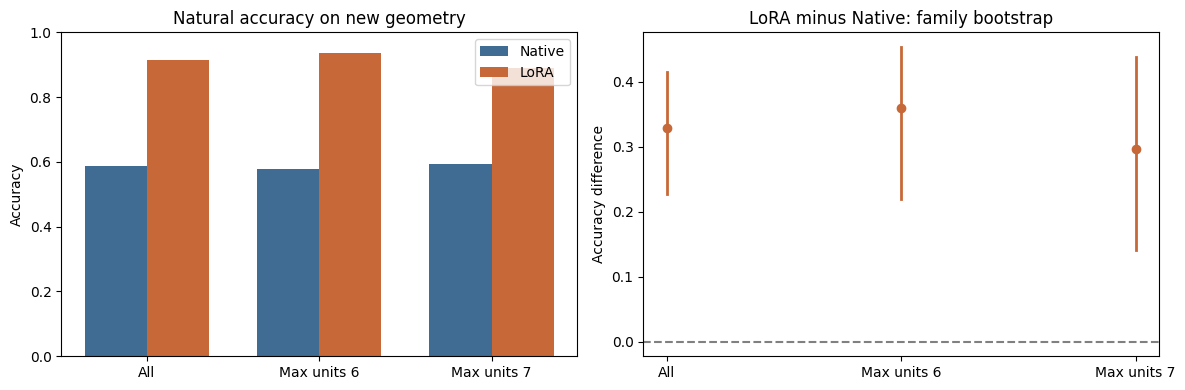

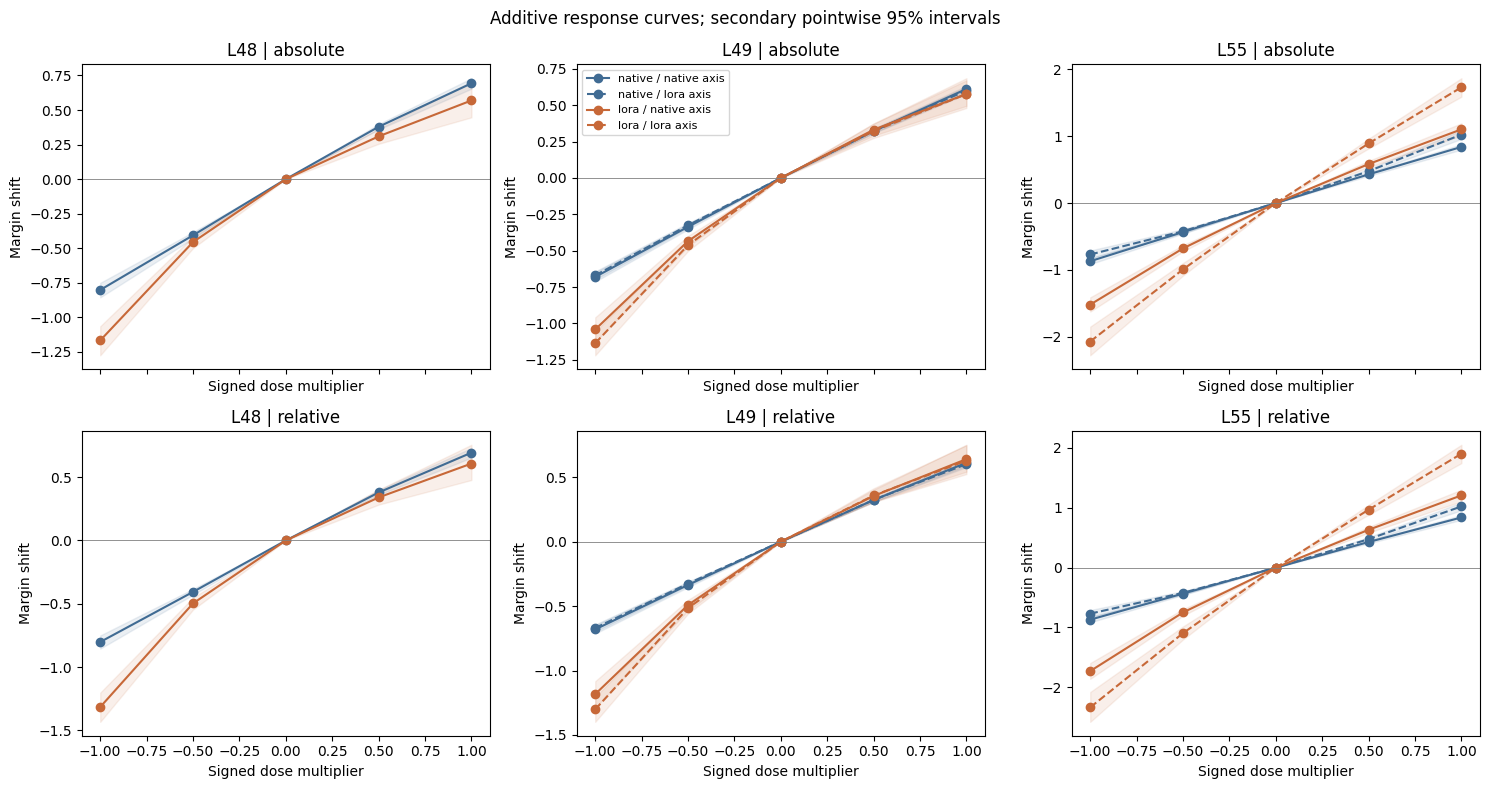

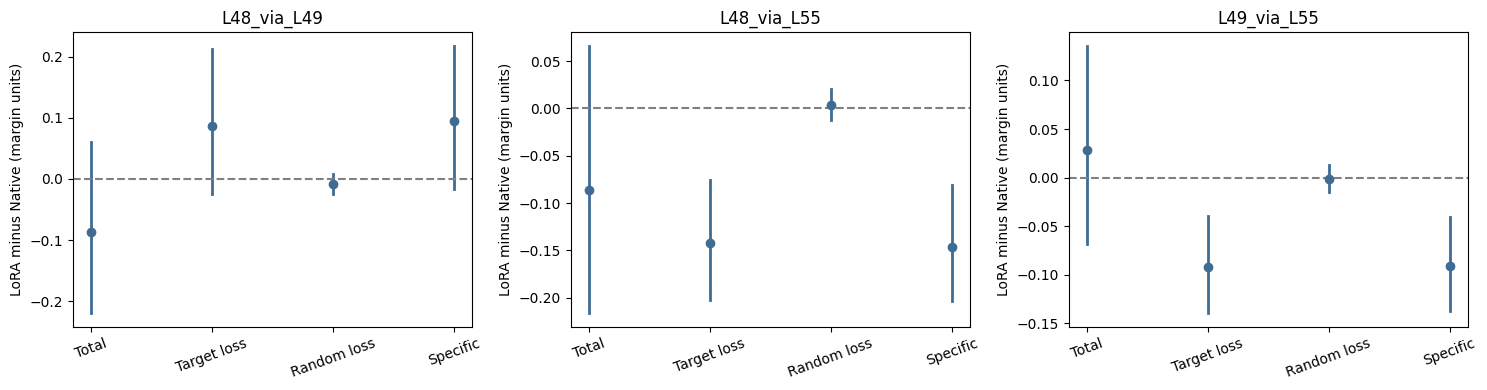

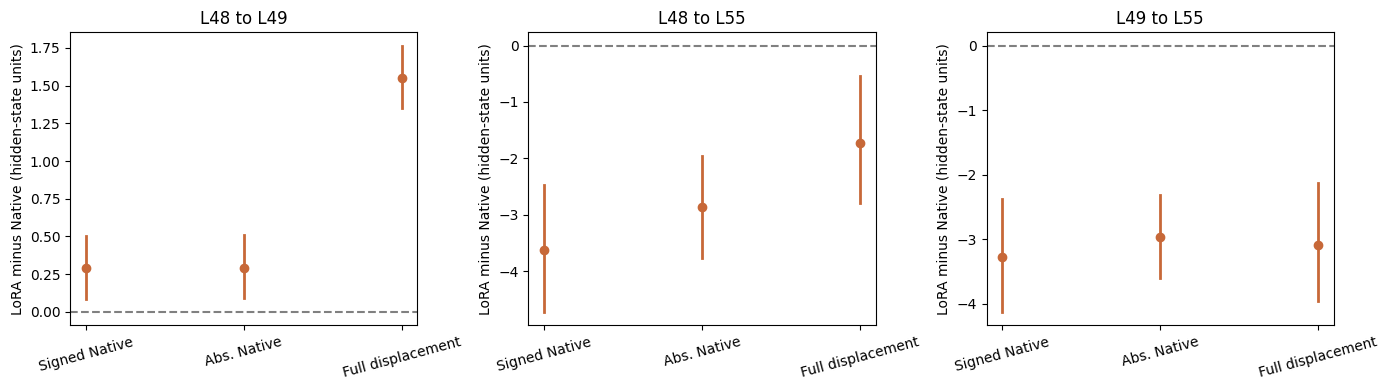

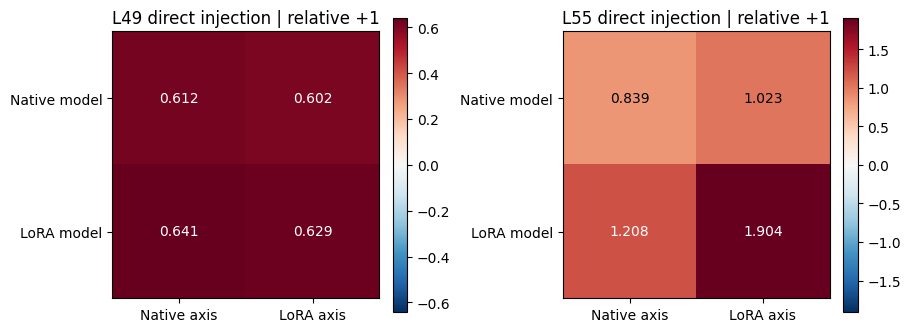

In [13]:
%%cell_progress 12/13 Display figures for all key comparisons
cell_stage('Display figures for all key comparisons')

def errorbar_row(ax,row,x,color):
    ax.scatter(x,row['estimate'],color=color,zorder=3)
    if pd.notna(row['ci_low']) and pd.notna(row['ci_high']):ax.plot([x,x],[row['ci_low'],row['ci_high']],color=color,lw=2)

fig,axes=plt.subplots(1,2,figsize=(12,4))
f=behavior[behavior.scope.isin(['all','max_units'])].reset_index(drop=True);x=np.arange(len(f))
axes[0].bar(x-.18,f.native_mean,.36,label='Native',color='#406b93');axes[0].bar(x+.18,f.lora_mean,.36,label='LoRA',color='#c76838')
axes[0].set_xticks(x,['All' if r.scope=='all' else 'Max units '+r.value for r in f.itertuples()]);axes[0].set_ylim(0,1)
axes[0].set(title='Natural accuracy on new geometry',ylabel='Accuracy');axes[0].legend()
for i,r in f.iterrows():errorbar_row(axes[1],r,i,'#c76838')
axes[1].set_xticks(x,axes[0].get_xticklabels());axes[1].axhline(0,color='gray',ls='--')
axes[1].set(title='LoRA minus Native: family bootstrap',ylabel='Accuracy difference')
fig.tight_layout();fig.savefig(FIGURE_DIR/'behavior.png',dpi=180);display(fig);plt.close(fig)

fig,axes=plt.subplots(2,3,figsize=(15,8),sharex=True)
for j,layer in enumerate((48,49,55)):
    for i,scale in enumerate(('absolute','relative')):
        ax=axes[i,j]
        for model,color in [('native','#406b93'),('lora','#c76838')]:
            for source,style in [('native','-'),('lora','--')]:
                sub=curves[(curves.model==model)&(curves.layer==layer)&(curves.axis==source)&(curves.scale==scale)]
                if sub.empty:continue
                # The clean-referenced zero-dose effect is exactly zero, not a fitted point.
                sub=pd.concat([sub,pd.DataFrame([{'dose':0.,'estimate':0.,'ci_low':0.,'ci_high':0.}])],ignore_index=True).sort_values('dose')
                ax.plot(sub.dose,sub.estimate,style,marker='o',color=color,label=f'{model} / {source} axis')
                ax.fill_between(sub.dose.to_numpy(),sub.ci_low.to_numpy(dtype=float),sub.ci_high.to_numpy(dtype=float),color=color,alpha=.10)
        ax.axhline(0,color='gray',lw=.6);ax.set(title=f'L{layer} | {scale}',xlabel='Signed dose multiplier',ylabel='Margin shift')
axes[0,1].legend(fontsize=8);fig.suptitle('Additive response curves; secondary pointwise 95% intervals')
fig.tight_layout();fig.savefig(FIGURE_DIR/'dose_curves.png',dpi=180);display(fig);plt.close(fig)

fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,route in zip(axes,ROUTES):
    sub=decomposition[(decomposition.route==route)&(decomposition.scale=='relative')].set_index('component')
    fields=['total_effect','target_block_loss','random_block_loss','specific_loss']
    for i,key in enumerate(fields):errorbar_row(ax,sub.loc[key],i,'#406b93')
    ax.axhline(0,color='gray',ls='--');ax.set_xticks(range(4),['Total','Target loss','Random loss','Specific'],rotation=20)
    ax.set(title=route,ylabel='LoRA minus Native (margin units)')
fig.tight_layout();fig.savefig(FIGURE_DIR/'block_decomposition.png',dpi=180);display(fig);plt.close(fig)

fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,(layer,read) in zip(axes,[(48,49),(48,55),(49,55)]):
    sub=selected_projection[(selected_projection.input_layer==layer)&(selected_projection.read_layer==read)].set_index('metric')
    fields=['projection_on_native','absolute_projection_on_native','displacement_from_own_clean_norm']
    for i,key in enumerate(fields):errorbar_row(ax,sub.loc[key],i,'#c76838')
    ax.axhline(0,color='gray',ls='--');ax.set_xticks(range(3),['Signed Native','Abs. Native','Full displacement'],rotation=15)
    ax.set(title=f'L{layer} to L{read}',ylabel='LoRA minus Native (hidden-state units)')
fig.tight_layout();fig.savefig(FIGURE_DIR/'transport_changes.png',dpi=180);display(fig);plt.close(fig)

fig,axes=plt.subplots(1,2,figsize=(9,4),constrained_layout=True)
for ax,layer in zip(axes,[49,55]):
    row=injection_cross[(injection_cross.layer==layer)&(injection_cross.scale=='relative')&(injection_cross.dose==1)].iloc[0]
    values=np.array([[row.native_recipient_native_axis,row.native_recipient_lora_axis],[row.lora_recipient_native_axis,row.lora_recipient_lora_axis]])
    limit=max(float(np.abs(values).max()),1e-8)
    im=ax.imshow(values,cmap='RdBu_r',vmin=-limit,vmax=limit)
    for i,j in itertools.product(range(2),repeat=2):ax.text(j,i,f'{values[i,j]:.3f}',ha='center',va='center',color='white' if abs(values[i,j])>.6*limit else 'black')
    ax.set_xticks([0,1],['Native axis','LoRA axis']);ax.set_yticks([0,1],['Native model','LoRA model'])
    ax.set_title(f'L{layer} direct injection | relative +1');fig.colorbar(im,ax=ax,shrink=.75)
fig.savefig(FIGURE_DIR/'direct_axis_crossover.png',dpi=180);display(fig);plt.close(fig)

In [14]:
%%cell_progress 13/13 Display Chinese report and export review files
cell_stage('Display Chinese report and export review files')

def fmt(value):return '不可估计' if value is None or pd.isna(value) else f'{float(value):.4f}'
def ci(row):return '['+fmt(row['ci_low'])+', '+fmt(row['ci_high'])+']'
overall=behavior[behavior.scope=='all'].iloc[0]
lines=['# AxisDose review_bundle：CPU 分析报告','',
    f'来源 ZIP：`{SOURCE_ZIP.name}`；SHA256：`{SOURCE_ZIP_HASH}`。',
    f'已核对 {N_FAMILIES} 个独立物理家族、{len(clean)} 个 clean 输入、{len(patch)} 个干预记录、{len(traces)} 个逐层 trace。',
    '所有包内完成清单哈希通过；剂量 CSV 重建了原先省略的 dose_inventory 身份，完整运行身份链匹配；六项主检验从干预明细重新计算并匹配原表。',
    '没有加载模型或重跑推理。紧凑包没有提供轴张量、clean 张量、原始逐条件 logits 和原图，因此这里只能核对已导出记录及其内部一致性。',
    '', '## 1. 自然行为',
    f"Native 准确率 {overall.native_mean:.2%}（{int(overall.native_correct)}/{int(overall.inputs_per_model)}）；LoRA {overall.lora_mean:.2%}（{int(overall.lora_correct)}/{int(overall.inputs_per_model)}）。",
    f'LoRA−Native = {overall.estimate:.4f}；逐 family bootstrap 95% CI {ci(overall)}。',
    '输入级转变计数：'+ '；'.join(f'{r.transition}={r.paired_inputs}' for r in transition_table.itertuples())+'。这些输入计数不作为独立样本数。']
for r in behavior[behavior.scope=='max_units'].to_dict('records'):
    lines.append(f"- 最大砝码数 {r['value']}：Native={r['native_mean']:.2%}，LoRA={r['lora_mean']:.2%}，差={fmt(r['estimate'])}，95% CI {ci(r)}；n={r['n_families']} 家族。")
lines+=['','## 2. 原六项主要检验（原 Holm 校正）',
    '固定 Native 注入、relative +1。recipient_change_native_clamp 是固定 Native 阻断轴的模型差；model_x_clamp_source 是接收模型 × 阻断轴来源的交互。']
for r in primary.to_dict('records'):
    status='通过原六项 Holm 校正' if r['p_holm']<.05 else '未通过原六项 Holm 校正'
    lines.append(f"- {r['test']}：差/交互={fmt(r['estimate'])}；95% CI {ci(r)}；Holm p={r['p_holm']:.6f}；{status}。")
lines+=['','## 3. 剂量与直接注入方向（次级分析）',
    '以下区间为逐项描述性区间，没有新增多重检验后的显著性结论。注入方向交互和上面的阻断方向交互是不同问题。']
for r in injection_cross[(injection_cross.scale=='relative')&(injection_cross.dose==1)].to_dict('records'):
    lines.append(f"- L{r['layer']} 直接注入：Native 模型使用 Native/LoRA 轴的平均效应={fmt(r['native_recipient_native_axis'])}/{fmt(r['native_recipient_lora_axis'])}；LoRA 模型相应为 {fmt(r['lora_recipient_native_axis'])}/{fmt(r['lora_recipient_lora_axis'])}。模型 × 注入轴交互={fmt(r['estimate'])}，95% CI {ci(r)}。")
for r in dose_modification[(dose_modification.axis=='native')&(dose_modification.dose==1)].to_dict('records'):
    lines.append(f"- L{r['layer']}：相对匹配相较绝对剂量，使 LoRA−Native 的总效应差改变 {fmt(r['estimate'])}；95% CI {ci(r)}。这检验一种预定尺度规则，不排除其他非线性尺度因素。")
for r in oddness[(oddness.axis=='native')&(oddness.scale=='relative')&(oddness.amplitude==1)].to_dict('records'):
    lines.append(f"- L{r['layer']} 正负不对称 E(+1)+E(−1)：Native={fmt(r['native_asymmetry'])}，LoRA={fmt(r['lora_asymmetry'])}；模型差={fmt(r['estimate'])}，95% CI {ci(r)}。不能只看正剂量推断整体可干预性。")
lines+=['','## 4. 阻断效应分解与状态传递（次级分析）',
    '特异损失 = 目标阻断损失 − 随机阻断损失；目标损失 = 总干预效应 − 目标阻断后响应 + 自钳制响应。不能把随机阻断后仍存在的响应本身误认为随机轴造成的损伤。']
for route in ROUTES:
    f=decomposition[(decomposition.route==route)&(decomposition.scale=='relative')].set_index('component')
    lines.append(f"- {route}：总效应模型差={fmt(f.loc['total_effect','estimate'])}，目标阻断损失差={fmt(f.loc['target_block_loss','estimate'])}，随机阻断损失差={fmt(f.loc['random_block_loss','estimate'])}，最终特异损失差={fmt(f.loc['specific_loss','estimate'])}。")
for r in selected_projection[selected_projection.metric.isin(['projection_on_native','absolute_projection_on_native'])].to_dict('records'):
    lines.append(f"- L{r['input_layer']}→L{r['read_layer']}，{r['metric']}：Native={fmt(r['native_mean'])}，LoRA={fmt(r['lora_mean'])}，差={fmt(r['estimate'])}，95% CI {ci(r)}。")
lines+=['符号投影、绝对投影和完整状态位移是不同量。即使绝对投影接近，也不能断言 signed state 相同；比较被诱导的投影与直接 L55 响应，只能提供后续机制实验的定位线索。',
    '', '## 5. 边界与解释范围',
    '6/7 块、左右侧、字母映射、物理线索冲突类型的完整表格已显示并保存。6 与 7 块的模型效应差使用独立组重采样；左右与映射使用同一 family 内的配对交互。小分组区间可能很宽，单家族子组不产生置信区间。',
    '自然 margin 与阻断损失的关系仅是描述性关联，不证明“天花板解释”或自然行为改善的中介。原方向支持由 Native 研究选出，两模型使用同算法同支持，但不保证 LoRA 方向最优。',
    '新集合排除了指定的 SFT、原物理审计、方向支持及旧 paired cohort 几何；并非所有历史项目都未见过任何相似图形的证明，也不代表原分布总体准确率。',
    '本轮不能证明自然回答使用乘法算法、唯一电路、通路消失或自然因果中介。L48 始终是 Native 轴。未通过校正的交互不写成“已恢复”，未显著不写成“等价”。',
    '', '## 6. 后续优先级',
    '先结合三个证据层面定位：总干预响应是否改变；特定 L55 坐标的阻断贡献是否改变；相同上游干预产生的带符号投影是否改变。',
    '如果只有坐标投影减少，可以考虑后续匹配诱导投影幅度的干预；如果投影与输出响应关系也变了，需要进一步控制模型状态和非线性。当前分析不自动宣判其中一个解释成立。',
    '无需因为某个次级区间不跨零而立即开展大规模新实验；先把主检验、控制分解和边界表共同用于论文表述。',
    '', '## 主要文件',
    '`KEY_RESULTS.json`、`tables/` 全部 CSV、`figures/` 五张图、`source_integrity.json`、`reconstructed_identity.json`、`control_checks.json`、`numeric_reconstruction_checks.csv`。']
report='\n'.join(lines)+'\n'
report_path=OUTPUT_ROOT/'CPU_REVIEW_REPORT_ZH.md';report_path.write_text(report,encoding='utf-8')
key_results={'audit_identity':AUDIT_ID,'source_run_identity':completion['run_identity'],'n_families':N_FAMILIES,
    'axis_geometry':records(axis_geometry),
    'source_limits':source_limits,'primary_six_tests':records(primary),'behavior':records(behavior),
    'transition_counts':records(transition_table),'consistency':records(consistency),
    'injection_cross_relative_plus1':records(injection_cross[(injection_cross.scale=='relative')&(injection_cross.dose==1)]),
    'total_native_axis_plus1':records(total_changes[(total_changes.axis=='native')&(total_changes.dose==1)]),
    'dose_modification_native_axis_plus1':records(dose_modification[(dose_modification.axis=='native')&(dose_modification.dose==1)]),
    'block_decomposition_relative':records(decomposition[decomposition.scale=='relative']),
    'projection_relative_native_injection_plus1':records(selected_projection),
    'route_boundaries':records(boundaries),'boundary_interactions':records(boundary_interactions),'control_checks':control,
    'secondary_intervals_are_pointwise':True,'new_confirmatory_tests_added':False}
write_json(OUTPUT_ROOT/'KEY_RESULTS.json',key_results)
require(sha256_file(SOURCE_ZIP)==SOURCE_ZIP_HASH,'Input ZIP changed during analysis.')
outputs={p.relative_to(OUTPUT_ROOT).as_posix():sha256_file(p) for p in sorted(OUTPUT_ROOT.rglob('*')) if p.is_file() and p.name!='RUN_COMPLETE.json'}
write_json(OUTPUT_ROOT/'RUN_COMPLETE.json',{'status':'complete','audit_identity':AUDIT_ID,'source_run':completion['run_identity'],
    'outputs':outputs,'completed_utc':datetime.now(timezone.utc).isoformat(),'no_model_inference':True})
archive_path=OUTPUT_BASE/('axis_dose_cpu_review_'+SOURCE_ZIP_HASH.split(':')[1][:12]+'.zip')
with zipfile.ZipFile(archive_path,'w',compression=zipfile.ZIP_DEFLATED) as archive:
    for name in [*outputs,'RUN_COMPLETE.json']:archive.write(OUTPUT_ROOT/name,arcname=name)
display(Markdown(report))
print('Report:',report_path)
print('Review ZIP:',archive_path)
print('Finished. The executed notebook now displays the critical numerical results.')

Display Chinese report and export review files:  92%|#########2| 12/13 [00:00<?, ?cell/s]

# AxisDose review_bundle：CPU 分析报告

来源 ZIP：`review_bundle.zip`；SHA256：`sha256:5154fe82d3152f7f0fa5fa1022188df4bbfa340197b2a0445f4238acc0815f33`。
已核对 32 个独立物理家族、256 个 clean 输入、17920 个干预记录、53760 个逐层 trace。
所有包内完成清单哈希通过；剂量 CSV 重建了原先省略的 dose_inventory 身份，完整运行身份链匹配；六项主检验从干预明细重新计算并匹配原表。
没有加载模型或重跑推理。紧凑包没有提供轴张量、clean 张量、原始逐条件 logits 和原图，因此这里只能核对已导出记录及其内部一致性。

## 1. 自然行为
Native 准确率 58.59%（75/128）；LoRA 91.41%（117/128）。
LoRA−Native = 0.3281；逐 family bootstrap 95% CI [0.2266, 0.4141]。
输入级转变计数：repaired=47；regressed=5；both_correct=70；both_wrong=6。这些输入计数不作为独立样本数。
- 最大砝码数 6：Native=57.81%，LoRA=93.75%，差=0.3594，95% CI [0.2188, 0.4531]；n=16 家族。
- 最大砝码数 7：Native=59.38%，LoRA=89.06%，差=0.2969，95% CI [0.1406, 0.4375]；n=16 家族。

## 2. 原六项主要检验（原 Holm 校正）
固定 Native 注入、relative +1。recipient_change_native_clamp 是固定 Native 阻断轴的模型差；model_x_clamp_source 是接收模型 × 阻断轴来源的交互。
- L48_via_L49__recipient_change_native_clamp：差/交互=0.0947；95% CI [-0.0156, 0.2207]；Holm p=0.410013；未通过原六项 Holm 校正。
- L48_via_L49__model_x_clamp_source：差/交互=-0.0010；95% CI [-0.0361, 0.0322]；Holm p=0.930986；未通过原六项 Holm 校正。
- L48_via_L55__recipient_change_native_clamp：差/交互=-0.1465；95% CI [-0.2051, -0.0811]；Holm p=0.001556；通过原六项 Holm 校正。
- L48_via_L55__model_x_clamp_source：差/交互=-0.0283；95% CI [-0.0928, 0.0352]；Holm p=0.817462；未通过原六项 Holm 校正。
- L49_via_L55__recipient_change_native_clamp：差/交互=-0.0908；95% CI [-0.1357, -0.0410]；Holm p=0.006332；通过原六项 Holm 校正。
- L49_via_L55__model_x_clamp_source：差/交互=0.0547；95% CI [0.0059, 0.1025]；Holm p=0.143125；未通过原六项 Holm 校正。

## 3. 剂量与直接注入方向（次级分析）
以下区间为逐项描述性区间，没有新增多重检验后的显著性结论。注入方向交互和上面的阻断方向交互是不同问题。
- L49 直接注入：Native 模型使用 Native/LoRA 轴的平均效应=0.6123/0.6016；LoRA 模型相应为 0.6406/0.6289。模型 × 注入轴交互=-0.0010，95% CI [-0.0273, 0.0273]。
- L55 直接注入：Native 模型使用 Native/LoRA 轴的平均效应=0.8389/1.0234；LoRA 模型相应为 1.2080/1.9043。模型 × 注入轴交互=0.5117，95% CI [0.3730, 0.6279]。
- L48：相对匹配相较绝对剂量，使 LoRA−Native 的总效应差改变 0.0381；95% CI [0.0195, 0.0557]。这检验一种预定尺度规则，不排除其他非线性尺度因素。
- L49：相对匹配相较绝对剂量，使 LoRA−Native 的总效应差改变 0.0625；95% CI [0.0420, 0.0840]。这检验一种预定尺度规则，不排除其他非线性尺度因素。
- L55：相对匹配相较绝对剂量，使 LoRA−Native 的总效应差改变 0.1064；95% CI [0.0840, 0.1279]。这检验一种预定尺度规则，不排除其他非线性尺度因素。
- L48 正负不对称 E(+1)+E(−1)：Native=-0.1084，LoRA=-0.7080；模型差=-0.5996，95% CI [-0.7891, -0.3926]。不能只看正剂量推断整体可干预性。
- L49 正负不对称 E(+1)+E(−1)：Native=-0.0684，LoRA=-0.5430；模型差=-0.4746，95% CI [-0.6230, -0.3008]。不能只看正剂量推断整体可干预性。
- L55 正负不对称 E(+1)+E(−1)：Native=-0.0303，LoRA=-0.5205；模型差=-0.4902，95% CI [-0.6074, -0.3584]。不能只看正剂量推断整体可干预性。

## 4. 阻断效应分解与状态传递（次级分析）
特异损失 = 目标阻断损失 − 随机阻断损失；目标损失 = 总干预效应 − 目标阻断后响应 + 自钳制响应。不能把随机阻断后仍存在的响应本身误认为随机轴造成的损伤。
- L48_via_L49：总效应模型差=-0.0859，目标阻断损失差=0.0859，随机阻断损失差=-0.0088，最终特异损失差=0.0947。
- L48_via_L55：总效应模型差=-0.0859，目标阻断损失差=-0.1426，随机阻断损失差=0.0039，最终特异损失差=-0.1465。
- L49_via_L55：总效应模型差=0.0283，目标阻断损失差=-0.0918，随机阻断损失差=-0.0010，最终特异损失差=-0.0908。
- L48→L49，projection_on_native：Native=12.9355，LoRA=13.2267，差=0.2911，95% CI [0.0877, 0.5057]。
- L48→L49，absolute_projection_on_native：Native=12.9355，LoRA=13.2267，差=0.2911，95% CI [0.0907, 0.5095]。
- L48→L55，projection_on_native：Native=3.8734，LoRA=0.2487，差=-3.6247，95% CI [-4.7255, -2.4791]。
- L48→L55，absolute_projection_on_native：Native=8.5246，LoRA=5.6616，差=-2.8629，95% CI [-3.7647, -1.9563]。
- L49→L55，projection_on_native：Native=4.7338，LoRA=1.4566，差=-3.2772，95% CI [-4.1263, -2.3697]。
- L49→L55，absolute_projection_on_native：Native=8.7598，LoRA=5.7888，差=-2.9710，95% CI [-3.5994, -2.3151]。
符号投影、绝对投影和完整状态位移是不同量。即使绝对投影接近，也不能断言 signed state 相同；比较被诱导的投影与直接 L55 响应，只能提供后续机制实验的定位线索。

## 5. 边界与解释范围
6/7 块、左右侧、字母映射、物理线索冲突类型的完整表格已显示并保存。6 与 7 块的模型效应差使用独立组重采样；左右与映射使用同一 family 内的配对交互。小分组区间可能很宽，单家族子组不产生置信区间。
自然 margin 与阻断损失的关系仅是描述性关联，不证明“天花板解释”或自然行为改善的中介。原方向支持由 Native 研究选出，两模型使用同算法同支持，但不保证 LoRA 方向最优。
新集合排除了指定的 SFT、原物理审计、方向支持及旧 paired cohort 几何；并非所有历史项目都未见过任何相似图形的证明，也不代表原分布总体准确率。
本轮不能证明自然回答使用乘法算法、唯一电路、通路消失或自然因果中介。L48 始终是 Native 轴。未通过校正的交互不写成“已恢复”，未显著不写成“等价”。

## 6. 后续优先级
先结合三个证据层面定位：总干预响应是否改变；特定 L55 坐标的阻断贡献是否改变；相同上游干预产生的带符号投影是否改变。
如果只有坐标投影减少，可以考虑后续匹配诱导投影幅度的干预；如果投影与输出响应关系也变了，需要进一步控制模型状态和非线性。当前分析不自动宣判其中一个解释成立。
无需因为某个次级区间不跨零而立即开展大规模新实验；先把主检验、控制分解和边界表共同用于论文表述。

## 主要文件
`KEY_RESULTS.json`、`tables/` 全部 CSV、`figures/` 五张图、`source_integrity.json`、`reconstructed_identity.json`、`control_checks.json`、`numeric_reconstruction_checks.csv`。


Report: /content/drive/MyDrive/VisualTorque/results/qwen27b_axis_dose_review_cpu_v1/5154fe82d315/CPU_REVIEW_REPORT_ZH.md
Review ZIP: /content/drive/MyDrive/VisualTorque/results/qwen27b_axis_dose_review_cpu_v1/axis_dose_cpu_review_5154fe82d315.zip
Finished. The executed notebook now displays the critical numerical results.
